# Caffeine & Sleep Time Planner (Set, Logic, Sequence)
**ปัญหา:** ช่วงสอบนักศึกษาดื่มกาแฟ แต่คาเฟอีนค้างในร่างกายหลายชั่วโมง ทำให้นอนไม่หลับ

**วัตถุประสงค์:** บอกว่าดื่มกาแฟแล้ว **นอนได้ตามเวลาที่ตั้งใจหรือไม่** และ **นอนได้ตั้งแต่กี่โมง**

## สูตร: คาเฟอีนลดลงครึ่งหนึ่งทุก 5 ชั่วโมง
$$C(t) = D \times \left(\tfrac{1}{2}\right)^{t/5}$$
$D$ = คาเฟอีนที่ดื่ม (mg), $t$ = ชั่วโมงหลังดื่ม · นอนได้เมื่อเหลือ **≤ 50 mg** · ไม่ควรดื่มเกิน **400 mg/วัน**

## ภาพรวมการทำงานของโปรแกรม

โปรแกรมทำงานเป็นลำดับ 5 ขั้น โดยแต่ละขั้นอยู่ในเซลล์ของตัวเอง:

```
ผู้ใช้กรอก: ปริมาณคาเฟอีน, เวลาดื่ม, เวลาอยากนอน, เวลาตื่น
        │
        ▼
[Sequence]  คำนวณคาเฟอีนที่เหลือในแต่ละชั่วโมง  aₙ = D · rⁿ
        │
        ▼
[Set]       A = ชั่วโมงที่คาเฟอีน ≤ 50 mg,  B = ชั่วโมงที่อยากนอน
        │
        ▼
[Logic]     p = (B ⊆ A),  q = (D ≤ 400)   →   นอนได้ ⇔ p ∧ q
        │
        ▼
ผลลัพธ์: ข้อความบอกว่านอนได้ไหม + เวลาที่นอนได้เร็วสุด + ปริมาณที่ดื่มได้สูงสุด + กราฟ
```

| เซลล์ | ทำอะไร |
|---|---|
| ค่าคงที่และสูตร | เก็บเกณฑ์ 50 mg / 400 mg และฟังก์ชันคำนวณคาเฟอีนที่เหลือ |
| `make_sets` | สร้างเซต A และ B จากเวลาที่ผู้ใช้กรอก |
| `check_sleep` | สร้างประพจน์ p และ q แล้วส่งค่าความจริงกลับ |
| `max_dose` | ใช้ลำดับเรขาคณิตหาว่าดื่มได้มากสุดกี่ mg |
| รับค่า + `plan` + `main` | รับค่าจากผู้ใช้อย่างปลอดภัย แล้วรวมทุกส่วนเพื่อแสดงผลและกราฟ |
| ทดสอบ 3 กรณี | ใช้ `assert` ยืนยันว่าผลถูกต้องครบทุกเงื่อนไขของ Logic |
| สาธิต | เรียก `main()` ให้ผู้ใช้กรอกข้อมูลเอง |

**หมายเหตุเรื่องเวลา:** ภายในโปรแกรมนับชั่วโมงต่อเนื่องเกินเที่ยงคืนได้ เช่น 01:00 ของวันถัดไปเก็บเป็น `25` และ 07:00 วันถัดไปเป็น `31` เพื่อให้ลบเวลากันได้ตรง ๆ แล้วค่อยแปลงกลับเป็นนาฬิกาตอนแสดงผล

### คำอธิบายเซลล์: ค่าคงที่และสูตรคาเฟอีน

**มีอะไรบ้าง**
- `import matplotlib.pyplot as plt` ไลบรารีวาดกราฟ ใช้ในฟังก์ชัน `plan`
- `SLEEP_LIMIT = 50` เกณฑ์คาเฟอีนที่ถือว่านอนหลับได้ (mg)
- `DAILY_LIMIT = 400` ปริมาณสูงสุดที่ไม่ควรดื่มเกินต่อวัน (mg)
- `caffeine_left(dose, hours)` คำนวณคาเฟอีนที่เหลือ
- `show_time(hour)` แปลงตัวเลขชั่วโมงเป็นข้อความเวลา

**ออกแบบอย่างไร**
- ตั้งเกณฑ์เป็นค่าคงที่ (ตัวพิมพ์ใหญ่) ไว้ที่เดียว ถ้าจะเปลี่ยนเกณฑ์ก็แก้บรรทัดเดียว ทุกฟังก์ชันจะใช้ค่าใหม่ทันที

**ทำงานอย่างไร**
- `caffeine_left` คือสูตร $C(t) = D \times 0.5^{t/5}$ ตรง ๆ: ทุก 5 ชั่วโมงคาเฟอีนเหลือครึ่งหนึ่ง  
  ตัวอย่าง: ดื่ม 96 mg ผ่านไป 5 ชั่วโมง → `caffeine_left(96, 5)` = **48 mg**
- `show_time` ใช้ `hour % 24` ตัดส่วนที่เกินวันออก แล้วจัดรูปแบบเป็น 2 หลัก  
  ตัวอย่าง: `show_time(25)` → `"01:00"`, `show_time(31)` → `"07:00"`

In [1]:
import matplotlib.pyplot as plt

SLEEP_LIMIT = 50   # mg
DAILY_LIMIT = 400  # mg

def caffeine_left(dose, hours):
    return dose * 0.5 ** (hours / 5)

def show_time(hour):          # 25 -> "01:00"
    return f"{hour % 24:02d}:00"

## หัวข้อที่ 1: Set (Lab 2)
- $A$ = ชั่วโมงที่คาเฟอีน ≤ 50 mg (**นอนได้**)
- $B$ = ชั่วโมงที่ **อยากนอน** (ตั้งแต่เข้านอนจนก่อนตื่น)
- $A \cap B$ = ชั่วโมงที่นอนได้จริง · $B - A$ = ชั่วโมงที่อยากนอนแต่ยังนอนไม่ได้

### คำอธิบายเซลล์: `make_sets` สร้างเซต A และ B (Set)

**รับค่า:** `dose` (mg), `drink` (เวลาดื่ม), `bed` (เวลาอยากนอน), `wake` (เวลาตื่น) เป็นชั่วโมง 0–23  
**ส่งกลับ:** เซต `A` และ `B`

**ทำงานอย่างไร (3 ขั้น)**
1. **ปรับเวลาให้ต่อเนื่อง**
   - ถ้า `bed < drink` แปลว่านอนหลังเที่ยงคืน จึงบวก 24 ให้เป็นวันถัดไป
   - `while wake <= bed` บวก 24 จนเวลาตื่นอยู่หลังเวลานอนเสมอ  
   ตัวอย่าง: ดื่ม 20, นอน 23, ตื่น 7 → ตื่นกลายเป็น 31 (07:00 วันถัดไป)
2. **สร้างเซต A (ชั่วโมงที่นอนได้)** วนทุกชั่วโมง `h` ตั้งแต่เวลาดื่มถึงเวลาตื่น คำนวณคาเฟอีนที่เหลือหลังดื่มไป `h - drink` ชั่วโมง ถ้า ≤ 50 mg ก็ใส่ `h` ลงในเซต  
   เขียนแบบเซต: $A = \{\, h \mid drink \le h \le wake,\ C(h - drink) \le 50 \,\}$
3. **สร้างเซต B (ชั่วโมงที่อยากนอน)** `set(range(bed, wake))` คือทุกชั่วโมงตั้งแต่เข้านอนจนถึงก่อนตื่น (แต่ละสมาชิกแทนชั่วโมงที่เริ่มต้นที่เวลานั้น)

**ตัวอย่างกรณี 2** (96 mg ดื่ม 20:00 นอน 23:00 ตื่น 07:00)
- A = {25, 26, …, 31} → นอนได้ตั้งแต่ 01:00
- B = {23, 24, …, 30} → อยากนอน 23:00 ถึง 07:00
- A ∩ B = {25, …, 30} → ชั่วโมงที่นอนได้จริง
- B − A = {23, 24} → 23:00 และ 00:00 อยากนอนแต่คาเฟอีนยังสูงเกิน

In [2]:
def make_sets(dose, drink, bed, wake):
    if bed < drink:        # นอนหลังเที่ยงคืน = วันถัดไป
        bed += 24
    while wake <= bed:     # ตื่นหลังเวลานอน
        wake += 24

    A = set()
    for h in range(drink, wake + 1):
        if caffeine_left(dose, h - drink) <= SLEEP_LIMIT:
            A.add(h)
    B = set(range(bed, wake))
    return A, B

## หัวข้อที่ 2: Logic (Lab 3)
- $p$: ช่วงที่อยากนอนปลอดภัยทั้งหมด ($B \subseteq A$)
- $q$: ดื่มไม่เกิน 400 mg
- **นอนได้ ⇔ $p \land q$** ถ้านอนไม่ได้ ดูว่า $\lnot p$ หรือ $\lnot q$ เป็นจริง

### คำอธิบายเซลล์: `check_sleep` ตรวจเงื่อนไขด้วยตรรกศาสตร์ (Logic)

**มีอะไรบ้าง:** ประพจน์ 2 ตัว
- `p = B <= A` ในภาษา Python เครื่องหมาย `<=` ระหว่างเซตแปลว่า **เป็นสับเซต** ($B \subseteq A$) คือทุกชั่วโมงที่อยากนอนต้องปลอดภัย
- `q = dose <= DAILY_LIMIT` ดื่มไม่เกิน 400 mg

**ทำงานอย่างไร:** ส่งค่าความจริง `(p, q)` กลับไป แล้วฟังก์ชัน `plan` ใช้สรุปผลว่า **นอนได้ ⇔ p ∧ q**

**ตารางค่าความจริง**

| p | q | p ∧ q | ความหมาย |
|---|---|---|---|
| T | T | T | ✅ นอนได้ตามเวลาที่ตั้งใจ |
| F | T | F | ❌ คาเฟอีนยังเกิน 50 mg ตอนนอน (¬p) |
| T | F | F | ❌ ดื่มเกิน 400 mg ต่อวัน (¬q) |
| F | F | F | ❌ ผิดทั้งสองเงื่อนไข |

**ออกแบบอย่างไร:** แยกเป็นฟังก์ชันเล็ก ๆ ที่ส่งค่ากลับแทนการพิมพ์ เพื่อให้ทดสอบด้วย `assert` ได้ง่าย

In [3]:
def check_sleep(dose, A, B):
    p = B <= A                 # B ⊆ A
    q = dose <= DAILY_LIMIT
    return p, q

## หัวข้อที่ 3: Sequence (Lab 4)
คาเฟอีนแต่ละชั่วโมงเป็น **ลำดับเรขาคณิต** (geometric sequence)

$$a_n = D \cdot r^n, \qquad r = 0.5^{1/5} \approx 0.87$$

- $D$ = คาเฟอีนที่ดื่ม (mg), $n$ = เวลานอน − เวลาดื่ม (ชั่วโมง)
- นอนได้เมื่อ $a_n \le 50$ ดังนั้น **ดื่มได้ไม่เกิน**

$$D \le \frac{50}{r^n}$$

และต้องไม่เกิน 400 mg/วัน

### คำอธิบายเซลล์: `max_dose` หาปริมาณที่ดื่มได้มากสุด (Sequence)

**แนวคิด:** ถ้ามองคาเฟอีนเป็นรายชั่วโมง จะได้ **ลำดับเรขาคณิต** $a_n = D \cdot r^n$
- `R = 0.5 ** (1/5)` ≈ **0.8706** คืออัตราส่วนร่วม: แต่ละชั่วโมงคาเฟอีนเหลือประมาณ 87% ของชั่วโมงก่อน (คูณกัน 5 ครั้ง $r^5 = 0.5$ จึงตรงกับครึ่งชีวิต 5 ชั่วโมง)

**ที่มาของสูตร:** อยากให้ตอนนอนเหลือไม่เกิน 50 mg  
$$D \cdot r^n \le 50 \;\Rightarrow\; D \le \frac{50}{r^n}$$

**ทำงานอย่างไร**
1. ถ้านอนหลังเที่ยงคืน (`bed < drink`) บวก 24 ให้เวลานอน
2. `n = bed - drink` คือจำนวนชั่วโมงจากดื่มถึงนอน
3. `limit = 50 / R ** n` คำนวณตามสูตร
4. `int(limit + 1e-9)` ปัดลงเป็นจำนวนเต็ม โดยบวกค่าเล็กมาก ๆ กันปัญหาทศนิยมของคอมพิวเตอร์ (เช่น 199.99999999 ควรเป็น 200)
5. `min(..., DAILY_LIMIT)` ไม่ให้เกิน 400 mg/วัน แม้สูตรจะยอมให้มากกว่านั้น

**ตัวอย่าง**
- ดื่ม 12:00 นอน 22:00 → n = 10, $r^{10} = 0.25$ → 50 / 0.25 = **200 mg**
- ดื่ม 20:00 นอน 23:00 → n = 3, $r^{3} ≈ 0.66$ → 50 / 0.66 ≈ 75.8 → **75 mg**

In [4]:
R = 0.5 ** (1 / 5)   # r ≈ 0.87

def max_dose(drink, bed):
    if bed < drink:          # นอนหลังเที่ยงคืน
        bed += 24
    n = bed - drink
    limit = SLEEP_LIMIT / R ** n
    return min(int(limit + 1e-9), DAILY_LIMIT)

### คำอธิบายเซลล์: รับค่าจากผู้ใช้ + `plan` + `main`

เซลล์นี้มี 4 ฟังก์ชัน ทำหน้าที่เชื่อมผู้ใช้กับส่วนคณิตศาสตร์ด้านบน

**1. `ask_number(text, low, high)` รับตัวเลข (ใช้กับปริมาณคาเฟอีน 1–1000 mg)**
- วน `while True` ถามซ้ำจนกว่าจะได้ค่าที่ถูกต้อง
- `isdigit()` กันข้อความที่ไม่ใช่จำนวนเต็มบวก เช่น `abc`, `-5`, `12.5`
- ตรวจช่วง `low <= value <= high` ถ้าเกินช่วงก็เตือนแล้วถามใหม่
- พารามิเตอร์ `input_fn=input` ออกแบบไว้ให้ตอนทดสอบส่งฟังก์ชันกรอกปลอมเข้าไปแทนการพิมพ์จริงได้

**2. `ask_time(text)` รับเวลา**
- ยอมรับได้ทั้ง `21`, `21:00` และ `21.00` (แปลง `.` เป็น `:` ก่อน)
- ถ้ามี `:` ต้องแยกได้ 2 ส่วนพอดี และนาทีต้องเป็น `00` เพราะโมเดลคิดเป็นรายชั่วโมง
- ชั่วโมงต้องอยู่ในช่วง 0–23
- ค่าผิดทุกแบบจะเกิด `ValueError` ซึ่งถูกจับไว้ แล้วพิมพ์ข้อความเตือนและถามใหม่ (เช่น `21:30`, `25`, `abc`)

**3. `plan(dose, drink, bed, wake, show_plot=True)` หัวใจของโปรแกรม**
1. เรียก `make_sets` ได้ A, B → เรียก `check_sleep` ได้ p, q
2. พิมพ์ผลตามค่าความจริง: ¬p → คาเฟอีนยังเกิน, ¬q → ดื่มเกิน 400 mg, p ∧ q → นอนได้
3. ถ้า A ไม่ว่าง พิมพ์ **เวลาที่นอนได้เร็วสุด** = `min(A)` (ชั่วโมงแรกที่คาเฟอีน ≤ 50 mg นับจากเวลาดื่ม จึงอาจเร็วกว่าเวลาที่ตั้งใจนอน)
4. พิมพ์คำแนะนำจาก Sequence: ถ้าจะนอนเวลานี้ควรดื่มไม่เกิน `max_dose` mg
5. ถ้า `show_plot=True` วาดกราฟ:
   - เส้นคาเฟอีนแต่ละชั่วโมงตั้งแต่ดื่มถึงเวลาตื่น
   - เส้นประสีแดงที่ 50 mg (เกณฑ์นอนได้)
   - เส้นจุดสีเทาที่เวลาเข้านอน
   - แกน x แสดงเป็นเวลานาฬิกาด้วย `show_time`
6. ส่งค่า `(p, q)` กลับ เพื่อให้เซลล์ทดสอบตรวจได้ (ตอนทดสอบใช้ `show_plot=False` จะได้ไม่วาดกราฟซ้ำ)

**4. `main()`** ถามค่า 4 อย่างตามลำดับ (คาเฟอีน, เวลาดื่ม, เวลานอน, เวลาตื่น) แล้วส่งให้ `plan`

In [5]:
def ask_number(text, low, high, input_fn=input):
    while True:
        user_input = input_fn(text)

        if not user_input.isdigit():
            print(f"กรุณากรอกเฉพาะจำนวน {low}-{high} และเท่านั้น")
            continue

        value = int(user_input)

        if low <= value <= high:
            return value
        else:
            print(f"กรุณากรอกเฉพาะจำนวน {low}-{high} เท่านั้น")

#แก้ให้เวลาสามารถเพิ่มจุดได้
def ask_time(text, input_fn=input):
    while True:
        user_input = input_fn(text).strip()

        try:
            # รองรับทั้ง 21.00 และ 21:00
            user_input = user_input.replace(".", ":")

            if ":" in user_input:
                parts = user_input.split(":")

                if len(parts) != 2:
                    raise ValueError

                hour = int(parts[0])
                minute = int(parts[1])

                # โปรเจกต์นี้คำนวณเป็นรายชั่วโมง
                if minute != 0:
                    raise ValueError

            else:
                hour = int(user_input)

            if 0 <= hour <= 23:
                return hour

        except ValueError:
            pass

        print("กรุณากรอกเวลา 0-23 เช่น 21, 21.00 หรือ 21:00")

def plan(dose, drink, bed, wake, show_plot=True):
    A, B = make_sets(dose, drink, bed, wake)
    p, q = check_sleep(dose, A, B)

    # User-friendly output
    if not p:
        print("\u274c คาเฟอีนยังเกิน 50 mg ตอนนอน")

    if not q:
        print("\u274c ดื่มเกิน 400 mg ต่อวัน")

    if p and q:
        print("\u2705 คุณสามารถนอนได้ตามเวลาที่ตั้งใจ")

    if A:
        print("\u23f0 นอนได้ตั้งแต่", show_time(min(A)))

    # Sequence
    print(f"\u2615 ถ้าจะนอน {show_time(bed)} ควรดื่มไม่เกิน {max_dose(drink, bed)} mg (ดื่มไป {dose} mg)")

    # กราฟ
    if show_plot:
        hours = list(range(drink, max(B) + 2))
        plt.plot(hours, [caffeine_left(dose, h - drink) for h in hours], marker="o", label="Caffeine")
        plt.axhline(SLEEP_LIMIT, color="red", linestyle="--", label="50 mg limit")
        plt.axvline(min(B), color="gray", linestyle=":", label="Bedtime")
        plt.xticks(hours, [show_time(h) for h in hours], rotation=60)
        plt.ylabel("Caffeine (mg)")
        plt.legend()
        plt.grid(True)
        plt.show()

    return p, q

def main():
    dose = ask_number("คาเฟอีนที่ดื่ม (mg): ", 1, 1000)
    drink = ask_time("เวลาที่ดื่ม (เช่น 21:00): ")
    bed = ask_time("เวลาที่อยากนอน (เช่น 23:00): ")
    wake = ask_time("เวลาที่ตื่น (เช่น 07:00): ")

    plan(dose, drink, bed, wake)


## ทดสอบ 3 กรณี

### คำอธิบายเซลล์: ทดสอบ 3 กรณี

**ออกแบบอย่างไร:** เลือก 3 กรณีให้ครอบคลุมทุกผลของ Logic ที่ต่างกัน

| กรณี | ข้อมูล | ค่าที่คาดหวัง (p, q) | ทดสอบอะไร |
|---|---|---|---|
| 1 | 96 mg ดื่ม 12:00 นอน 22:00 | (T, T) | นอนได้ปกติ |
| 2 | 96 mg ดื่ม 20:00 นอน 23:00 | (F, T) | ¬p คาเฟอีนยังสูงตอนนอน |
| 3 | 450 mg ดื่ม 06:00 นอน 23:00 | (T, F) | ¬q คาเฟอีนลดทันแต่ดื่มเกิน 400 mg |

**ทำงานอย่างไร**
1. `assert plan(...) == (p, q)` เรียกโปรแกรมจริงแล้วเทียบกับคำตอบที่คำนวณมือไว้ ถ้าไม่ตรงจะเกิด `AssertionError` และเซลล์หยุดทันที
2. `assert max_dose(...)` ตรวจส่วน Sequence: ได้ 200, 75 และ 400 mg (กรณี 3 ติดเพดาน 400)
3. ลูปสุดท้ายตรวจว่า **ส่วน Sequence กับส่วน Set/Logic ให้คำตอบตรงกัน**: ดื่มไม่เกิน `max_dose` ⇔ p ∧ q

ถ้าเซลล์รันจนพิมพ์ "✔ ผ่านทั้ง 3 กรณี" แปลว่าทุก `assert` ผ่านหมด

In [ ]:
print("=== กรณี 1: 96 mg ดื่ม 12:00 นอน 22:00 ===")
assert plan(96, 12, 22, 6, show_plot=False) == (True, True)     # นอนได้

print("\n=== กรณี 2: 96 mg ดื่ม 20:00 นอน 23:00 ===")
assert plan(96, 20, 23, 7, show_plot=False) == (False, True)    # not p

print("\n=== กรณี 3: 450 mg ดื่ม 06:00 นอน 23:00 ===")
assert plan(450, 6, 23, 7, show_plot=False) == (True, False)    # not q

# Sequence: ดื่มได้ไม่เกินกี่ mg
assert max_dose(12, 22) == 200
assert max_dose(20, 23) == 75
assert max_dose(6, 23) == 400   # ติดเพดาน 400 mg/วัน

# ดื่มไม่เกิน max_dose ⇔ p and q (ตรงกับ Logic)
for dose, drink, bed, wake in [(96, 12, 22, 6), (96, 20, 23, 7), (450, 6, 23, 7)]:
    p, q = check_sleep(dose, *make_sets(dose, drink, bed, wake))
    assert (dose <= max_dose(drink, bed)) == (p and q)

print("\n✔ ผ่านทั้ง 3 กรณี")

=== กรณี 1: 96 mg ดื่ม 12:00 นอน 22:00 ===
✅ คุณสามารถนอนได้ตามเวลาที่ตั้งใจ
⏰ นอนได้ตั้งแต่ 17:00
☕ ถ้าจะนอน 22:00 ควรดื่มไม่เกิน 200 mg (ดื่มไป 96 mg)

=== กรณี 2: 96 mg ดื่ม 20:00 นอน 23:00 ===
❌ คาเฟอีนยังเกิน 50 mg ตอนนอน
⏰ นอนได้ตั้งแต่ 01:00
☕ ถ้าจะนอน 23:00 ควรดื่มไม่เกิน 75 mg (ดื่มไป 96 mg)

=== กรณี 3: 450 mg ดื่ม 06:00 นอน 23:00 ===
❌ ดื่มเกิน 400 mg ต่อวัน
⏰ นอนได้ตั้งแต่ 22:00
☕ ถ้าจะนอน 23:00 ควรดื่มไม่เกิน 400 mg (ดื่มไป 450 mg)

✔ ผ่านทั้ง 3 กรณี


**สรุปผล:** กรณี 1 นอนได้ · กรณี 2 คาเฟอีนยังสูงตอน 23:00 ต้องรอถึง 01:00 · กรณี 3 คาเฟอีนลดทัน แต่ดื่มเกิน 400 mg

**Sequence:** ดื่มได้ไม่เกิน กรณี 1: 200 mg · กรณี 2: 75 mg (ดื่ม 96 จึงนอนไม่ได้) · กรณี 3: 400 mg (ติดเพดานต่อวัน)

**ข้อจำกัด:** ใช้ครึ่งชีวิต 5 ชม. เท่ากันทุกคน, ดื่มครั้งเดียว, คิดทีละชั่วโมง — เป็นค่าประมาณ ไม่ใช่คำแนะนำทางการแพทย์

## สาธิต: กรอกข้อมูลเอง

### คำอธิบายเซลล์: สาธิตด้วยข้อมูลของผู้ใช้

รันเซลล์ถัดไปแล้วกรอกค่า 4 อย่างตามที่โปรแกรมถาม ตัวอย่างที่ลองใช้ตอนนำเสนอได้:
- **96** mg, ดื่ม **20:00**, นอน **23:00**, ตื่น **07:00** → นอนไม่ได้ตามเวลา ต้องรอถึง 01:00 และควรดื่มไม่เกิน 75 mg
- ลองกรอกผิด เช่น `abc` หรือ `21:30` เพื่อแสดงว่าโปรแกรมเตือนและถามใหม่

คาเฟอีนที่ดื่ม (mg):  75
เวลาที่ดื่ม (เช่น 21:00):  12
เวลาที่อยากนอน (เช่น 23:00):  20
เวลาที่ตื่น (เช่น 07:00):  07


✅ คุณสามารถนอนได้ตามเวลาที่ตั้งใจ
⏰ นอนได้ตั้งแต่ 15:00
☕ ถ้าจะนอน 20:00 ควรดื่มไม่เกิน 151 mg (ดื่มไป 75 mg)


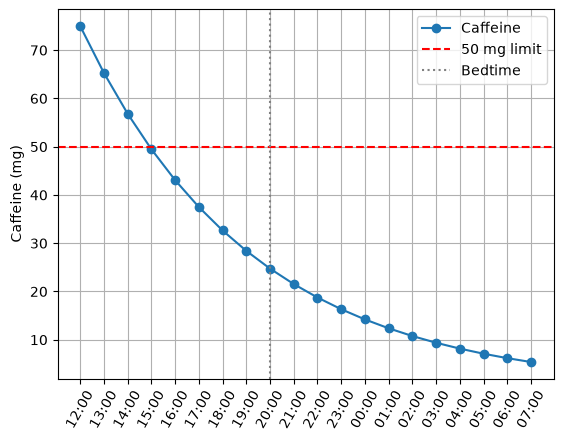

In [7]:
main()